# MTPFN on our A→B prior (with the transform class): standalone report and diagnosis

## Description

*Written 2026-11-03, before the diagnostics ran. Issue #20, branch `exp/20-mtpfn`. Arm A of notebook 12, as a standalone report. Arm R (the paper's own ICM prior) stays in notebook 12 and runs later.*

**Idea.** MTPFN (Li, Daulton, Müller, Wilson, Bakshy; SPIGM @ NeurIPS 2025) is the published PFN for in-context transfer between tasks.
- **Data.** Every task's points form a set. Each task also gets a [TASK] summary token.
- **Within a task** (intra-task attention): points and the [TASK] token attend to each other. The target's query points read only the target's own tokens.
- **Between tasks** (inter-task attention): only the [TASK] tokens attend to each other, so all transfer passes through one vector per task and layer.
- **Training.** The paper trains it on a robust ICM prior, where tasks share a lengthscale and correlate; with probability p a source task is unrelated.

**What we ask here.** Train the same architecture on *our* prior, the pilot-3 AIR prior:
- B: a dense source (128 points, noise σ_B);
- A: a scarce target (n_A ∈ 1..10);
- f_A(x) = g(T_θ(x)), with g a random MLP on the global ECDF scale;
- T_θ a monotone, box-preserving flow from the transform class, J ∈ {2, 4, 8, 16} coefficients;
- H0 (h = id) and Z0 (always related).

Then ask:
1. **Transfer.** How much better than A alone is it?
2. **Gap.** How far is it from the exact dense-B Bayes predictive (G-ref, J = 2), and from AIR (pilot 3, when its evaluation is in)?
3. **Diagnosis.** Why does it lose what it loses? Concretely: does it register B to A, that is, read B at T_θ(x*)?

**Setup.**
- **Model.** Width 128, N = 4 [intra, inter] pairs plus a final intra block, 4 heads, d_ff 512. That is 1.84M parameters, the AIR decoder + proposal budget, far below the paper's 23 × 512.
- **Training.** Bar output with AIR's bins (400 bins on [−0.25, 1.25]), so NLLs are on the same scale as AIR's. AdamW 1e-4, cosine, 100k steps × 64 tasks, seeds 0, 1, 2 (sweep `runs/mtpfn/pilot_20261103-132611`).
- **Evaluation.** Pilot 3's evaluation tasks: `eval_tasks(J, 256, seed 777, ecdf)`, J ∈ {2, 16}, n_A ∈ {1, 2, 3, 5, 10}, nested A designs.
- **References** on the same tasks:
  - pilot 3's clean A-only PFN, same seed (`aonly_pfn`);
  - G-ref at J = 2 (`gref`): exact Bayes given g, so a floor rather than a target.

**Diagnostics** (`experimental/mtpfn/diagnose.py`, mode `air_diag`, one run per seed):
- **D1 Transfer.** NLL(`aonly_pfn`) − NLL(MTPFN) per (J, n_A).
- **D2 Gap.** NLL(MTPFN) − NLL(`gref`), J = 2.
- **D3 Input controls** on the same tasks:
  - `b_registered`: B pulled into A's frame with the true θ. The gain over `b` is what MTPFN loses by having to handle the warp itself.
  - `b_other`: an unrelated B, i.e. another task's B.
  - `b_none`: B with only its [TASK] token, which is ≈ A-only and off-distribution.
- **D4 Where does it read B?**
  - Compute the sensitivity s_k = |∂E[y*|x*]/∂y_{B,k}| for every B point.
  - Summarise it as `read`, the sensitivity-weighted mean x_B, and `conc`, the share of sensitivity within ±0.05 of T_θ(x*).
  - Compare |read − T_θ(x*)| with |x* − T_θ(x*)|, i.e. with reading at x* itself.
- **D5 Calibration.** PIT of y* (128 tasks × 32 queries per cell).
- **D6 Warp size.** The D1 gain against the task's mean |T_θ(x) − x|.
- **Examples.** PPDs (mean and 5–95 % quantiles) on an x grid next to f_A, B, A and the G-ref predictive.

**Reading rules (pre-registered).** n_A ≥ 3, averaged over tasks; means over 3 seeds ± SE where that applies:
- **"MTPFN registers"**: median `conc` ≥ 0.5 and median |read − T| < median |x* − T|.
- **"It reads globally (summary transfer)"**: median `conc` < 0.2 and `read` ≈ 0.5 (|read − 0.5| < 0.1 for most x*).
- **"The warp is its bottleneck"**: NLL(`b`) − NLL(`b_registered`) ≥ 0.1 at n_A ≥ 2.
- **"Uses B"**: NLL(`b_other`) − NLL(`b`) ≥ 0.1.
- **Calibration**: reported as the PIT histogram plus the KS distance to uniform, no threshold.

**Expectation, written before the run.** MTPFN can pass B to A only through [TASK] summaries. So we expect it to use B (global level, scale, shape statistics), with a real gain over A-only at small n_A. But we expect it not to register B pointwise: low `conc`, a large `b_registered` gain, and a large gap to G-ref and to AIR, growing with J.

**Limits.** d = 1, Z0, H0 (pilot 3's scope). The model is smaller than the paper's. G-ref knows g exactly. Sensitivity is local (gradient), so it shows where the predictive *mean* reads, not the whole PPD.

## Results

Data: one `air_diag` run per seed on pilot 3's evaluation tasks; tables `ctrl`, `task_info`, `pit`, `sens`, `sensmap`, `ex`, `ex_pts` (experimental/mtpfn/diagnose.py).

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import kstest

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results").is_dir() and (p / "src").is_dir()), Path.cwd())
DIAG = "pilot_20261103-235449,pilot_20261103-235620,pilot_20261103-235751".split(",")  # one air_diag sweep per seed (results/mtpfn/<id>), in seed order
TRAIN = "pilot_20261103-132611"  # the air_train sweep (members = seeds)


def _dir(s):
    p = Path(s)
    return p if p.is_absolute() else ROOT / "results/mtpfn" / s / "tables"


def load(name):
    return pd.concat([pd.read_parquet(_dir(s) / f"{name}.parquet").assign(seed=k) for k, s in enumerate(DIAG)])


ctrl, info, pit, sens, smap, ex, pts = (load(k) for k in ("ctrl", "task_info", "pit", "sens", "sensmap", "ex",
                                                          "ex_pts"))  # fmt: skip
NS, SEEDS = sorted(ctrl.n_a.unique()), sorted(ctrl.seed.unique())
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]  # fixed categorical order
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "lines.linewidth": 2,
                     "lines.markersize": 6, "text.color": INK, "axes.labelcolor": MUTED, "font.size": 10,
                     "legend.frameon": False})  # fmt: skip
LAB = {"aonly_pfn": "A-only PFN (pilot 3, clean)", "b": "MTPFN (B as given)", "b_registered": "MTPFN, B pre-registered",
       "b_other": "MTPFN, unrelated B", "b_none": "MTPFN, B removed", "gref": "G-ref (exact, dense B)"}


def seed_mean(df, by):
    """Per-seed task means, then the mean over seeds ± SE over seeds (one seed: SE over tasks)."""
    if len(SEEDS) > 1:
        m = df.groupby(by + ["seed"]).nll.mean().groupby(by)
        return pd.DataFrame({"mean": m.mean(), "se": m.std(ddof=1) / np.sqrt(len(SEEDS))})
    g = df.groupby(by).nll
    return pd.DataFrame({"mean": g.mean(), "se": g.std(ddof=1) / np.sqrt(g.count())})


print("seeds:", SEEDS, "| tasks per (J, n_A):", ctrl.groupby(["seed", "J", "n_a", "input"]).size().max())

seeds: [np.int64(0), np.int64(1), np.int64(2)] | tasks per (J, n_A): 256


### Training

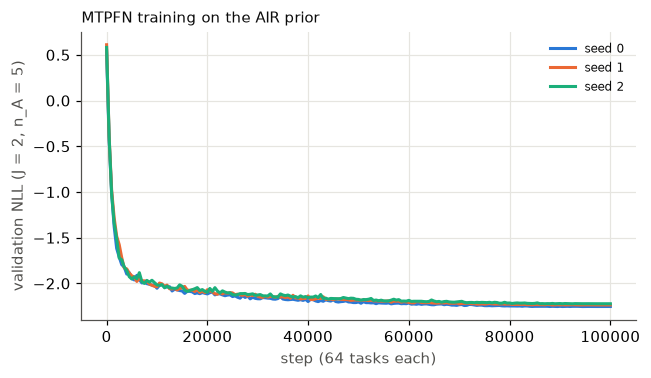

,member,step,val_nll,s
200,0,100000,-2.253,7955.559
401,1,100000,-2.235,10570.173
602,2,100000,-2.222,10464.406


In [ ]:
if TRAIN:
    tr = pd.read_parquet(ROOT / "results/mtpfn" / TRAIN / "tables" / "train.parquet")
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    for k, (m, d) in enumerate(tr.groupby("member")):
        ax.plot(d.step, d.val_nll, color=C[k], label=f"seed {m}")
    ax.set(xlabel="step (64 tasks each)", ylabel="validation NLL (J = 2, n_A = 5)")
    ax.set_title("MTPFN training on the AIR prior", loc="left", fontsize=10)
    ax.legend(fontsize=8)
    plt.show()
    display(tr.groupby("member").tail(1)[["member", "step", "val_nll", "s"]].round(3))

### D1–D3: transfer, gap to the exact reference, input controls

In [ ]:
piv = {}
for J in sorted(ctrl.J.unique()):
    t = seed_mean(ctrl[ctrl.J == J], ["n_a", "input"])
    piv[J] = t["mean"].unstack("input").round(3)
    print(f"J = {J}: mean NLL per query (lower is better); seeds {SEEDS}")
    display(piv[J][[c for c in LAB if c in piv[J]]].rename(columns=LAB))


def paired(J, a, b):
    """mean over tasks of NLL(a) - NLL(b), paired by (seed, task); mean ± SE as in seed_mean."""
    w = ctrl[ctrl.J == J].pivot_table(index=["seed", "n_a", "task"], columns="input", values="nll")
    d = (w[a] - w[b]).rename("nll").reset_index()
    return seed_mean(d, ["n_a"])


rows = []
for J in sorted(ctrl.J.unique()):
    for name, a, b in [("D1 transfer: A-only − MTPFN", "aonly_pfn", "b"),
                       ("D3 warp cost: MTPFN − MTPFN(B registered)", "b", "b_registered"),
                       ("D3 uses B: MTPFN(unrelated B) − MTPFN", "b_other", "b"),
                       ("D2 gap: MTPFN − G-ref", "b", "gref"),
                       ("registered gap: MTPFN(B registered) − G-ref", "b_registered", "gref")]:
        if a in ctrl.input.unique() and b in ctrl[ctrl.J == J].input.unique():
            p = paired(J, a, b)
            rows += [{"J": J, "quantity": name, "n_a": n, "value": f"{r['mean']:+.3f} ± {r['se']:.3f}"}
                     for n, r in p.iterrows()]
display(pd.DataFrame(rows).pivot_table(index=["J", "quantity"], columns="n_a", values="value", aggfunc="first"))

J = 2: mean NLL per query (lower is better); seeds [np.int64(0), np.int64(1), np.int64(2)]


input,"A-only PFN (pilot 3, clean)",MTPFN (B as given),"MTPFN, B pre-registered","MTPFN, unrelated B","MTPFN, B removed","G-ref (exact, dense B)"
n_a,,,,,,
1,-0.874,-1.922,-2.042,3.340,1.552,-2.123
2,-1.357,-2.040,-2.125,2.194,0.414,-2.293
3,-1.612,-2.126,-2.181,1.470,-0.161,-2.398
5,-1.902,-2.240,-2.263,0.592,-0.821,-2.517
10,-2.178,-2.388,-2.386,-0.353,-1.483,-2.640


J = 16: mean NLL per query (lower is better); seeds [np.int64(0), np.int64(1), np.int64(2)]


input,"A-only PFN (pilot 3, clean)",MTPFN (B as given),"MTPFN, B pre-registered","MTPFN, unrelated B","MTPFN, B removed"
n_a,,,,,
1,-0.905,-1.909,-2.008,3.254,1.432
2,-1.359,-2.009,-2.078,2.166,0.382
3,-1.595,-2.080,-2.117,1.530,-0.228
5,-1.850,-2.171,-2.190,0.739,-0.879
10,-2.140,-2.288,-2.293,-0.288,-1.503


n_a                                                         1   \
J  quantity                                                      
2  D1 transfer: A-only − MTPFN                  +1.048 ± 0.002   
   D2 gap: MTPFN − G-ref                        +0.201 ± 0.002   
   D3 uses B: MTPFN(unrelated B) − MTPFN        +5.262 ± 0.100   
   D3 warp cost: MTPFN − MTPFN(B registered)    +0.120 ± 0.001   
   registered gap: MTPFN(B registered) − G-ref  +0.081 ± 0.004   
16 D1 transfer: A-only − MTPFN                  +1.003 ± 0.001   
   D3 uses B: MTPFN(unrelated B) − MTPFN        +5.163 ± 0.105   
   D3 warp cost: MTPFN − MTPFN(B registered)    +0.099 ± 0.006   

n_a                                                         2   \
J  quantity                                                      
2  D1 transfer: A-only − MTPFN                  +0.683 ± 0.003   
   D2 gap: MTPFN − G-ref                        +0.254 ± 0.003   
   D3 uses B: MTPFN(unrelated B) − MTPFN        +4.234 ± 0.093   
   D3 warp cost: MTPFN − MTPFN(B registered)    +0.086 ± 0.002   
   registered gap: MTPFN(B registered) − G-ref  +0.168 ± 0.005   
16 D1 transfer: A-only − MTPFN                  +0.650 ± 0.002   
   D3 uses B: MTPFN(unrelated B) − MTPFN        +4.175 ± 0.109   
   D3 warp cost: MTPFN − MTPFN(B registered)    +0.068 ± 0.006   

n_a                                                         3   \
J  quantity                                                      
2  D1 transfer: A-only − MTPFN                  +0.514 ± 0.005   
   D2 gap: MTPFN − G-ref                        +0.271 ± 0.004   
   D3 uses B: MTPFN(unrelated B) − MTPFN        +3.596 ± 0.097   
   D3 warp cost: MTPFN − MTPFN(B registered)    +0.055 ± 0.004   
   registered gap: MTPFN(B registered) − G-ref  +0.216 ± 0.005   
16 D1 transfer: A-only − MTPFN                  +0.484 ± 0.005   
   D3 uses B: MTPFN(unrelated B) − MTPFN        +3.610 ± 0.100   
   D3 warp cost: MTPFN − MTPFN(B registered)    +0.037 ± 0.006   

n_a                                                         5               10  
J  quantity                                                                     
2  D1 transfer: A-only − MTPFN                  +0.338 ± 0.004  +0.211 ± 0.005  
   D2 gap: MTPFN − G-ref                        +0.276 ± 0.005  +0.251 ± 0.007  
   D3 uses B: MTPFN(unrelated B) − MTPFN        +2.832 ± 0.093  +2.035 ± 0.074  
   D3 warp cost: MTPFN − MTPFN(B registered)    +0.023 ± 0.002  -0.003 ± 0.002  
   registered gap: MTPFN(B registered) − G-ref  +0.254 ± 0.006  +0.254 ± 0.007  
16 D1 transfer: A-only − MTPFN                  +0.321 ± 0.005  +0.149 ± 0.007  
   D3 uses B: MTPFN(unrelated B) − MTPFN        +2.910 ± 0.094  +2.000 ± 0.070  
   D3 warp cost: MTPFN − MTPFN(B registered)    +0.019 ± 0.006  +0.005 ± 0.005

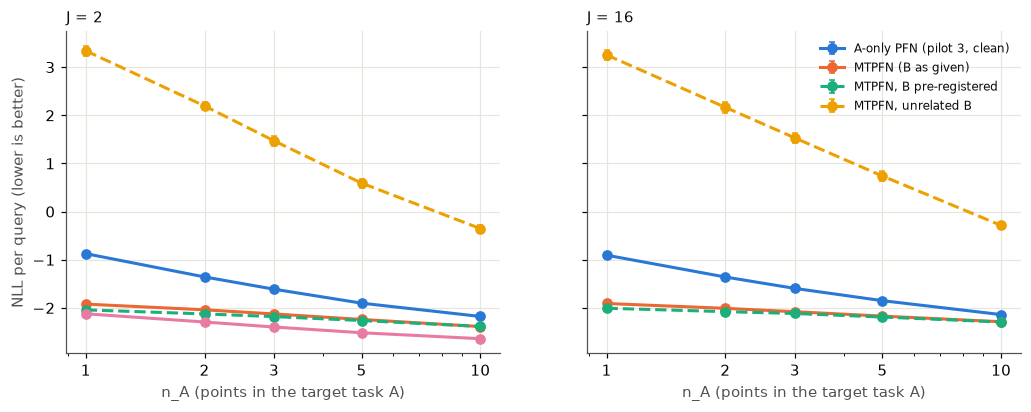

In [ ]:
Js = sorted(ctrl.J.unique())
fig, axs = plt.subplots(1, len(Js), figsize=(5.6 * len(Js), 3.8), sharey=True)
axs = np.atleast_1d(axs)
for ax, J in zip(axs, Js):
    t = seed_mean(ctrl[ctrl.J == J], ["input", "n_a"])
    for k, inp in enumerate(["aonly_pfn", "b", "b_registered", "b_other", "gref"]):
        if inp not in t.index.get_level_values(0):
            continue
        d = t.loc[inp]
        ls = "--" if inp in ("b_registered", "b_other") else "-"
        ax.errorbar(d.index, d["mean"], yerr=d["se"], color=C[k], ls=ls, marker="o", capsize=2, label=LAB[inp])
    ax.set(xscale="log", xticks=NS, xticklabels=NS, xlabel="n_A (points in the target task A)")
    ax.set_title(f"J = {J}", loc="left", fontsize=10)
axs[0].set_ylabel("NLL per query (lower is better)")
axs[-1].legend(fontsize=8, loc="upper right")
plt.show()

### D4: where does the MTPFN read B?

conc_median  read_err_median  identity_err_median  \
J  n_a                                                      
2  1          0.154            0.160                0.072   
   2          0.161            0.147                0.072   
   3          0.169            0.140                0.072   
   5          0.182            0.129                0.072   
   10         0.196            0.131                0.072   
16 1          0.162            0.165                0.092   
   2          0.170            0.156                0.092   
   3          0.176            0.147                0.092   
   5          0.183            0.144                0.092   
   10         0.197            0.136                0.092   

        share_read_near_middle  
J  n_a                          
2  1                     0.345  
   2                     0.353  
   3                     0.342  
   5                     0.328  
   10                    0.335  
16 1                     0.325  
   2                     0.347  
   3                     0.350  
   5                     0.347  
   10                    0.313

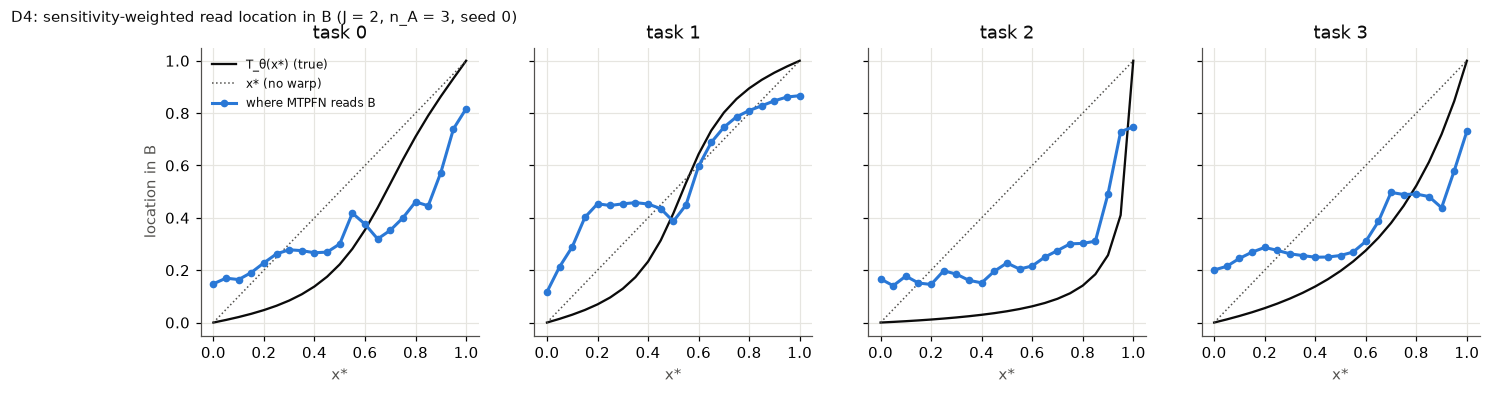

In [ ]:
s = sens.copy()
s["err_read"] = (s.read - s.true_t).abs()
s["err_id"] = (s.xq - s.true_t).abs()
s["read_mid"] = (s.read - 0.5).abs() < 0.1
tab4 = s.groupby(["J", "n_a"]).agg(conc_median=("conc", "median"), read_err_median=("err_read", "median"),
                                   identity_err_median=("err_id", "median"), share_read_near_middle=("read_mid", "mean"))
display(tab4.round(3))
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, (i, d) in zip(axs, s[(s.J == 2) & (s.n_a == 3) & (s.seed == 0)].groupby("task")):
    ax.plot(d.xq, d.true_t, color=INK, lw=1.5, label="T_θ(x*) (true)")
    ax.plot(d.xq, d.xq, color=MUTED, lw=1, ls=":", label="x* (no warp)")
    ax.plot(d.xq, d.read, color=C[0], marker="o", ms=4, label="where MTPFN reads B")
    ax.set(xlabel="x*", title=f"task {i}")
axs[0].set_ylabel("location in B")
axs[0].legend(fontsize=8)
plt.suptitle("D4: sensitivity-weighted read location in B (J = 2, n_A = 3, seed 0)", x=0.01, ha="left", fontsize=10)
plt.show()

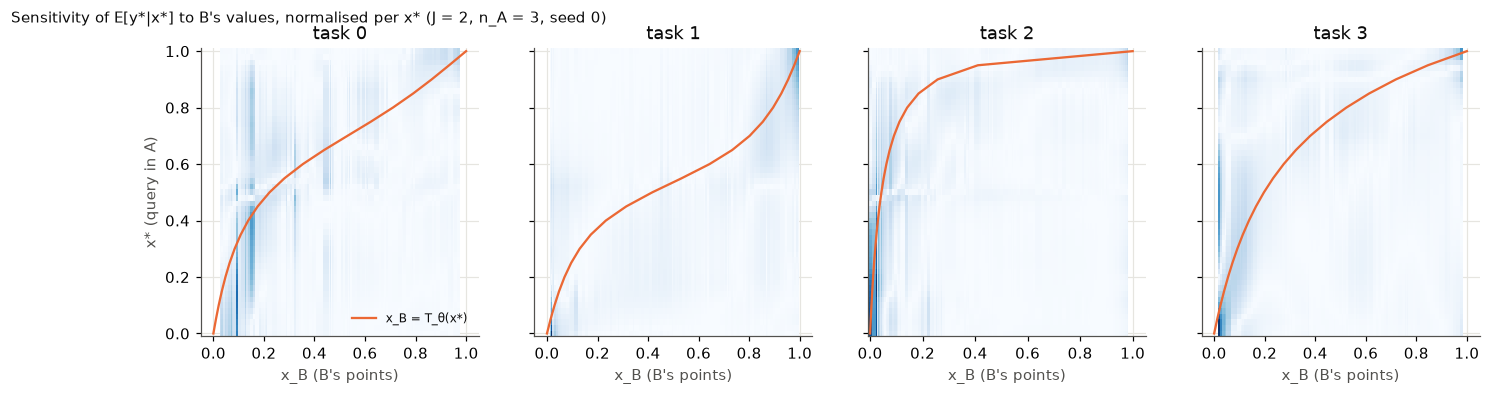

In [ ]:
sm = smap[(smap.J == 2) & (smap.n_a == 3) & (smap.seed == 0)]
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, (i, d) in zip(axs, sm.groupby("task")):
    m = d.pivot_table(index="xq", columns="xb", values="s")
    m = m.div(m.sum(axis=1), axis=0)
    ax.pcolormesh(m.columns, m.index, m.values, cmap="Blues", shading="nearest")
    tt = s[(s.J == 2) & (s.n_a == 3) & (s.seed == 0) & (s.task == i)]
    ax.plot(tt.true_t, tt.xq, color=C[1], lw=1.5, label="x_B = T_θ(x*)")
    ax.set(xlabel="x_B (B's points)", title=f"task {i}")
axs[0].set_ylabel("x* (query in A)")
axs[0].legend(fontsize=8, loc="lower right")
plt.suptitle("Sensitivity of E[y*|x*] to B's values, normalised per x* (J = 2, n_A = 3, seed 0)", x=0.01, ha="left",
             fontsize=10)  # fmt: skip
plt.show()

### D5: calibration

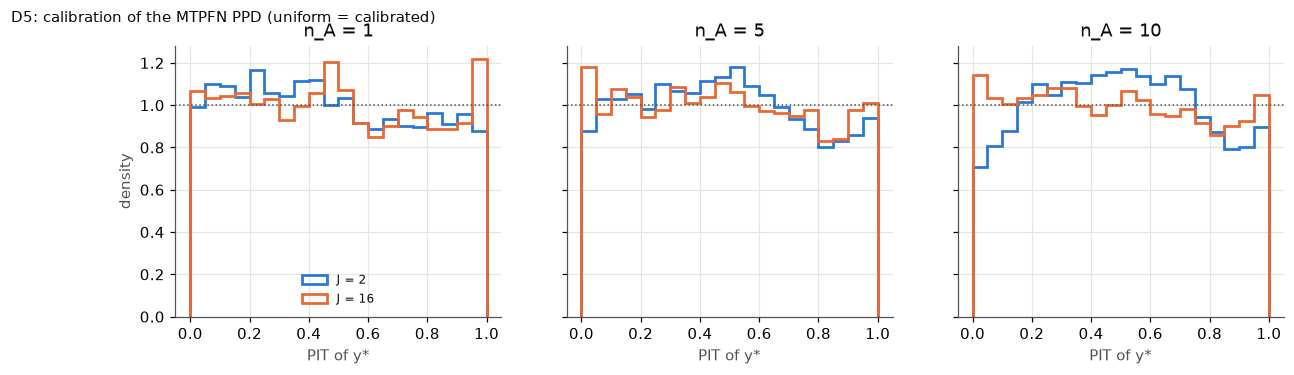

n_a,1,5,10
J,,,
2,0.038,0.039,0.035
16,0.026,0.025,0.024


In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
ksr = []
for ax, n in zip(axs, (1, 5, 10)):
    for k, J in enumerate(sorted(pit.J.unique())):
        v = pit[(pit.J == J) & (pit.n_a == n)].pit.values
        ax.hist(v, bins=20, range=(0, 1), density=True, histtype="step", color=C[k], lw=1.8, label=f"J = {J}")
        ksr.append({"J": J, "n_a": n, "ks_D": kstest(v, "uniform").statistic})
    ax.axhline(1, color=MUTED, lw=1, ls=":")
    ax.set(xlabel="PIT of y*", title=f"n_A = {n}")
axs[0].set_ylabel("density")
axs[0].legend(fontsize=8)
plt.suptitle("D5: calibration of the MTPFN PPD (uniform = calibrated)", x=0.01, ha="left", fontsize=10)
plt.show()
display(pd.DataFrame(ksr).pivot_table(index="J", columns="n_a", values="ks_D").round(3))

### D6: transfer and warp cost against the size of the warp

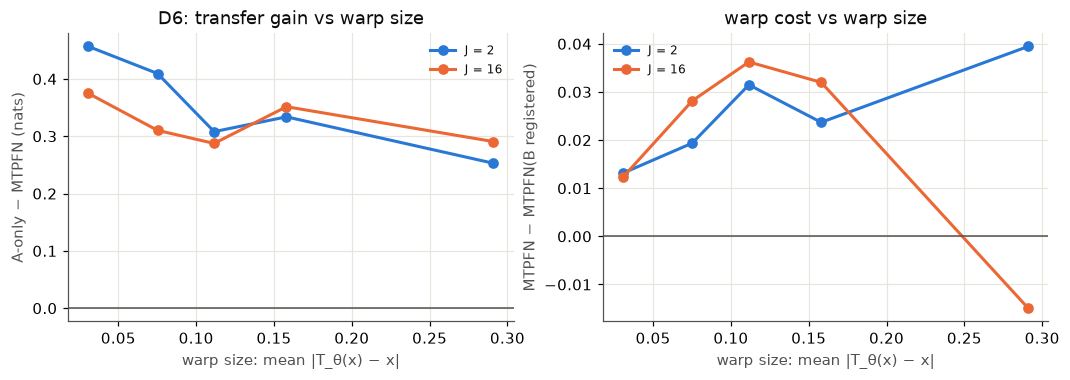

In [ ]:
w = ctrl.pivot_table(index=["seed", "J", "n_a", "task"], columns="input", values="nll").reset_index()
w = w.merge(info.drop_duplicates(["J", "task"])[["J", "task", "shift"]], on=["J", "task"])
w["shift_bin"] = pd.qcut(w["shift"], 5, duplicates="drop")
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.4))
for k, J in enumerate(sorted(w.J.unique())):
    d = w[(w.J == J) & (w.n_a >= 3)]
    if "aonly_pfn" in d:
        g = (d.aonly_pfn - d.b).groupby(d.shift_bin, observed=True).mean()
        axs[0].plot([iv.mid for iv in g.index], g.values, color=C[k], marker="o", label=f"J = {J}")
    g = (d.b - d.b_registered).groupby(d.shift_bin, observed=True).mean()
    axs[1].plot([iv.mid for iv in g.index], g.values, color=C[k], marker="o", label=f"J = {J}")
axs[0].set(xlabel="warp size: mean |T_θ(x) − x|", ylabel="A-only − MTPFN (nats)", title="D6: transfer gain vs warp size")
axs[1].set(xlabel="warp size: mean |T_θ(x) − x|", ylabel="MTPFN − MTPFN(B registered)", title="warp cost vs warp size")
for ax in axs:
    ax.axhline(0, color=MUTED, lw=1)
    ax.legend(fontsize=8)
plt.show()

### Examples

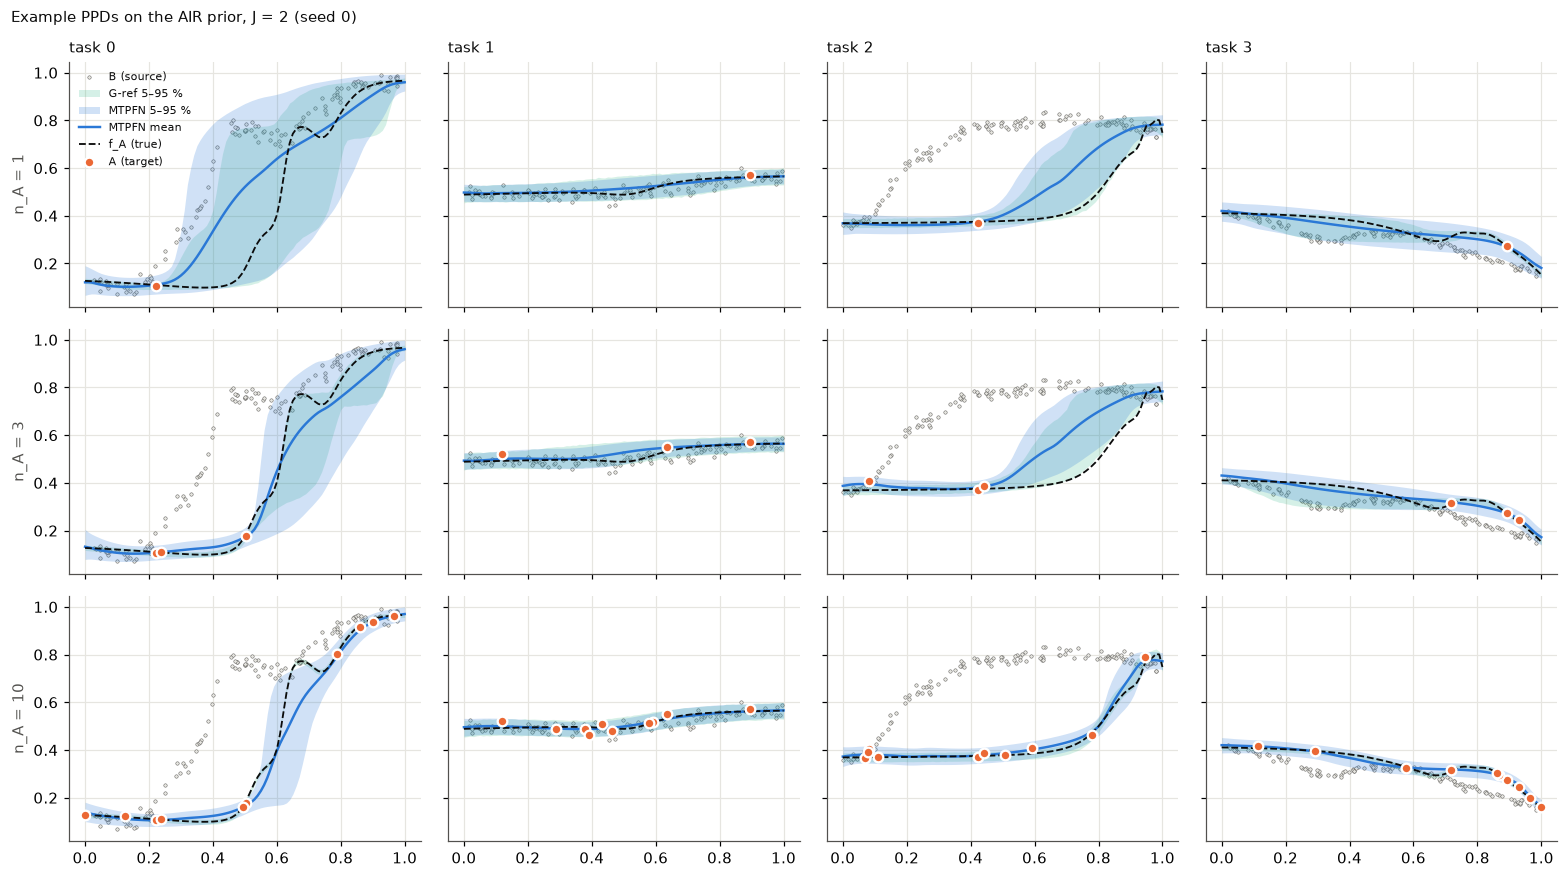

In [ ]:
e = ex[(ex.J == 2) & (ex.seed == 0)]
p = pts[(pts.J == 2) & (pts.seed == 0)]
tasks, nas = sorted(e.task.unique())[:4], sorted(e.n_a.unique())
fig, axs = plt.subplots(len(nas), len(tasks), figsize=(3.6 * len(tasks), 2.7 * len(nas)), sharex=True, sharey=True)
for r, n in enumerate(nas):
    for c, i in enumerate(tasks):
        ax = axs[r, c]
        d = e[(e.n_a == n) & (e.task == i)].pivot_table(index="x", columns="kind", values="value")
        pb = p[(p.n_a == n) & (p.task == i) & (p.set == "B")]
        pa = p[(p.n_a == n) & (p.task == i) & (p.set == "A")]
        ax.scatter(pb.x, pb.y, s=5, color=GRID, edgecolor=MUTED, lw=0.3, label="B (source)")
        if "gref_q5" in d:
            ax.fill_between(d.index, d.gref_q5, d.gref_q95, color=C[2], alpha=0.18, lw=0, label="G-ref 5–95 %")
        ax.fill_between(d.index, d.q5, d.q95, color=C[0], alpha=0.22, lw=0, label="MTPFN 5–95 %")
        ax.plot(d.index, d["mean"], color=C[0], lw=1.6, label="MTPFN mean")
        ax.plot(d.index, d.f_a, color=INK, lw=1.2, ls="--", label="f_A (true)")
        ax.scatter(pa.x, pa.y, s=40, color=C[1], edgecolor="white", lw=1.5, zorder=5, label="A (target)")
        if r == 0:
            ax.set_title(f"task {i}", loc="left", fontsize=10)
        if c == 0:
            ax.set_ylabel(f"n_A = {n}")
axs[0, 0].legend(fontsize=7, loc="upper left")
plt.suptitle("Example PPDs on the AIR prior, J = 2 (seed 0)", x=0.01, ha="left", fontsize=10)
plt.tight_layout()
plt.show()

### Pre-registered reading rules

In [ ]:
r = []
s3 = s[s.n_a >= 3]
for J in sorted(s.J.unique()):
    sj = s3[s3.J == J]
    cj = ctrl[(ctrl.J == J)]
    w = cj.pivot_table(index=["seed", "n_a", "task"], columns="input", values="nll").reset_index()
    reg = (w.b - w.b_registered)[w.n_a >= 2].mean()
    use = (w.b_other - w.b).mean()
    r += [{"J": J, "rule": "MTPFN registers (conc ≥ 0.5 and |read − T| < |x* − T|)",
           "measured": f"conc {sj.conc.median():.2f}; {sj.err_read.median():.3f} vs {sj.err_id.median():.3f}",
           "holds": bool(sj.conc.median() >= 0.5 and sj.err_read.median() < sj.err_id.median())},
          {"J": J, "rule": "reads globally (conc < 0.2 and read ≈ 0.5 for most x*)",
           "measured": f"conc {sj.conc.median():.2f}; share near 0.5 {sj.read_mid.mean():.2f}",
           "holds": bool(sj.conc.median() < 0.2 and sj.read_mid.mean() > 0.5)},
          {"J": J, "rule": "the warp is its bottleneck (b − b_registered ≥ 0.1, n_A ≥ 2)",
           "measured": f"{reg:+.3f}", "holds": bool(reg >= 0.1)},
          {"J": J, "rule": "uses B (b_other − b ≥ 0.1)", "measured": f"{use:+.3f}", "holds": bool(use >= 0.1)}]
display(pd.DataFrame(r))

,J,rule,measured,holds
0,2,MTPFN registers (conc ≥ 0.5 and |read − T| < |...,conc 0.18; 0.133 vs 0.072,False
1,2,reads globally (conc < 0.2 and read ≈ 0.5 for ...,conc 0.18; share near 0.5 0.33,False
2,2,the warp is its bottleneck (b − b_registered ≥...,+0.040,False
3,2,uses B (b_other − b ≥ 0.1),+3.592,True
4,16,MTPFN registers (conc ≥ 0.5 and |read − T| < |...,conc 0.18; 0.142 vs 0.092,False
5,16,reads globally (conc < 0.2 and read ≈ 0.5 for ...,conc 0.18; share near 0.5 0.34,False
6,16,the warp is its bottleneck (b − b_registered ≥...,+0.033,False
7,16,uses B (b_other − b ≥ 0.1),+3.572,True


## Interpretation (3 seeds, pilot 3's evaluation tasks, 2026-11-04)

Diagnostics `results/mtpfn/pilot_20261103-235449` / `-235620` / `-235751` (seeds 0 / 1 / 2, 256 tasks per cell,
generated on CUDA exactly as pilot 3's; checked: A-only and G-ref rows equal pilot 3's `a_only_clean` and `grid`,
e.g. −0.8735 and −2.1226 at J = 2, n_A = 1). Training `results/mtpfn/pilot_20261103-132611` (3/3 DONE; final val NLL
−2.25 / −2.24 / −2.22). ± = SE across seeds.

**Deviations.** The first diagnostics ran with n_eval = 128 (`pilot_20261103-160920`, `-190701`, `-220253`): the first
128 of pilot 3's 256 tasks (identical per task), so a subset, not other tasks. A local CPU rerun with 256 tasks
(`pilot_20261103-220644`, `-221440`, `-222230`) drew *different* tasks: `eval_tasks` uses a device-specific generator.
Only the final GPU runs above are the pre-registered tasks; the other runs agree qualitatively and are kept as
snapshots.

**D1 Transfer: large.** MTPFN beats pilot 3's clean A-only PFN by +1.05 / +0.68 / +0.51 / +0.34 / +0.21 nats per query
at n_A = 1 / 2 / 3 / 5 / 10 (J = 2; SE ≤ 0.005), and by +1.00 … +0.15 at J = 16. D3: it uses B (another task's B costs
+2.0 to +5.3 nats).

**D2 Gap to G-ref: 0.20–0.28 nats** at J = 2, flat in n_A.

**D3 The warp is not its bottleneck.** A B pre-registered with the true θ gains +0.12 at n_A = 1, +0.06 at n_A = 3 and
nothing at n_A = 10 (rule ≥ 0.1 at n_A ≥ 2: does not hold). Even with B registered, MTPFN stays 0.08–0.25 nats above
G-ref. So most of what it loses is not finding the correspondence but turning 128 noisy B points into an accurate
predictive for A (G-ref also knows g exactly, so part of this is not recoverable by any model).

**D4 It does not register, and does not read globally.** Median `conc` 0.15–0.20 (registers needs ≥ 0.5); its
sensitivity-weighted read location is further from T_θ(x*) (0.13–0.17) than plain identity (0.07–0.09); sensitivity
maps show vertical stripes (a few B points matter for every x*). It neither reads B at T(x*) nor at the middle: it
summarises B's shape and fits A with it, which on this prior's mostly mild warps carries most of the transfer.

**D5 Calibration** is fine (PIT KS distance 0.02–0.04).

**Paired comparison with AIR (pilot 3, same seed and task, notebook 11).** NLL(MTPFN) − NLL(AIR q-IS K = 32), mean over
3 seeds (± seed SE), positive = AIR better:

| | n_A = 1 | 2 | 3 | 5 | 10 |
|---|---|---|---|---|---|
| J = 2, AIR Σ = 0.1 | +0.070 ± 0.003 | +0.089 ± 0.007 | +0.092 ± 0.012 | +0.090 ± 0.011 | +0.072 ± 0.022 |
| J = 2, AIR Σ = 0 | +0.034 ± 0.003 | +0.062 ± 0.011 | +0.065 ± 0.005 | +0.094 ± 0.008 | +0.091 ± 0.022 |
| J = 16, AIR Σ = 0.1 | +0.033 ± 0.002 | +0.026 ± 0.005 | +0.025 ± 0.007 | +0.027 ± 0.007 | +0.030 ± 0.018 |
| J = 16, AIR Σ = 0 | −0.011 ± 0.012 | −0.012 ± 0.007 | −0.013 ± 0.008 | −0.018 ± 0.011 | −0.008 ± 0.014 |

AIR wins on 69–75 % of tasks at J = 2 (Σ = 0.1). At J = 16 the two are close: AIR (Σ = 0.1) is ahead by 0.03, and at
Σ = 0 MTPFN is level or marginally better. So the explicit transform latent buys 0.07–0.09 nats on the smooth J = 2
warps and little on the wiggly J = 16 warps at K = 32 — the opposite of the pre-registered expectation that MTPFN's
gap would grow with J.

**Pre-registered expectation vs outcome.** Expected: MTPFN uses B (yes), does not register (yes), a large
`b_registered` gain (no: ≤ 0.12, ~0 at n_A ≥ 5), a large gap to AIR growing with J (no: 0.07–0.09 at J = 2, ~0.03 at
J = 16).

**Proposed reading** (notebook 13 is a diagnosis, not a GO/NO-GO): MTPFN, at AIR's parameter budget, is a strong
baseline on our prior — most of AIR's transfer without any explicit correspondence — and AIR's advantage is real but
modest (0.07–0.09 nats at J = 2, 0.03 at J = 16). The remaining gap of both to G-ref is dominated by reading g from
noisy B (MTPFN) or by the decoder (AIR), not by the warp. Paper-scale MTPFN (23 × 512) is not needed to make this
point; it would be needed only to claim AIR beats the paper's model as published.
